# Lab1.2: Supervised Learning

The purpose of this notebook is to explore the linear regression model discussed in Chapter 2 of the book.

Work through the cells below, running each cell in turn. In various places you will see the words "TODO". Follow the instructions at these places and write code to complete the functions. There are also questions interspersed in the text.


In [1]:
# Math library
import numpy as np
# Plotting library
import matplotlib.pyplot as plt

### 1. Randomly Generate Data

In [3]:
# Create some input(x) / output data(y)
x = np.array([0.03, 0.19, 0.34, 0.46, 0.78, 0.81, 1.08, 1.18, 1.39, 1.60, 1.65, 1.90])
y = np.array([0.67, 0.85, 1.05, 1.0, 1.40, 1.5, 1.3, 1.54, 1.55, 1.68, 1.73, 1.6 ])

print(x)
print(y)

[0.03 0.19 0.34 0.46 0.78 0.81 1.08 1.18 1.39 1.6  1.65 1.9 ]
[0.67 0.85 1.05 1.   1.4  1.5  1.3  1.54 1.55 1.68 1.73 1.6 ]


### 2. 1D Linear Regression(one input, ane output)

---
The 1D linear regression model is defined as:

$$
y = \phi_0 + \phi_1 x
$$

Where:  

- $x$ → input  
- $\phi_0$ → bias / intercept  
- $\phi_1$ → slope / weight


In [4]:
# Define 1D linear regression model
def f(x, phi0, phi1):
  
  y = phi0+(x*phi1)

  return y

In [5]:
# Function to help plot the data
def plot(x, y, phi0, phi1):
    fig,ax = plt.subplots()
    ax.scatter(x,y)
    plt.xlim([0,2.0])
    plt.ylim([0,2.0])
    ax.set_xlabel('Input, $x$')
    ax.set_ylabel('Output, $y$')
    # Draw line
    x_line = np.arange(0, 2, 0.01)
    y_line = f(x_line, phi0, phi1)
    plt.plot(x_line, y_line,'b-',lw=2)

    plt.show()

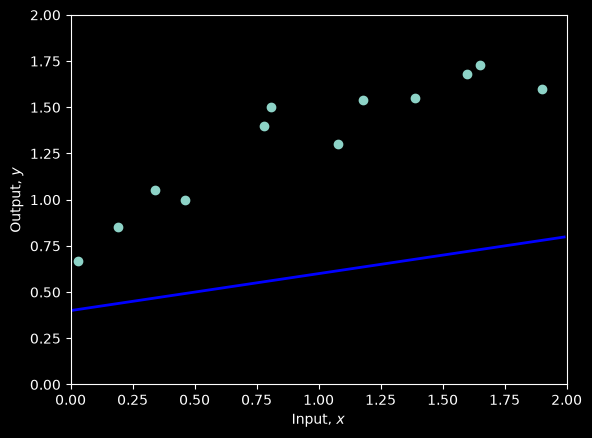

In [6]:
# Set the intercept and slope manually to see how the model fits the data
phi0 = 0.4 ; phi1 = 0.2
# Plot the data and the model
plot(x,y,phi0,phi1)

### 3. Loss Functions for 1D Linear Regression

<details>
<summary>1. Mean Squared Error (MSE)</summary>

$$
\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - (\phi_0 + \phi_1 x_i))^2
$$

**Explanation:**

- Measures the **average squared difference** between the predicted values and the actual values.  
- Squaring the error **penalizes large errors more heavily**, so MSE is **sensitive to outliers**.  
- Commonly used in **linear regression** because it has nice mathematical properties for optimization (differentiable, convex).  

</details>

......
<details>
<summary>2. Mean Absolute Error (MAE)</summary>

$$
\text{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - (\phi_0 + \phi_1 x_i)|
$$

**Explanation:**

- Measures the **average absolute difference** between the predicted values and the actual values.  
- Less sensitive to outliers compared to MSE because errors are **not squared**.  
- MAE is useful when you want a **robust metric** that treats all errors equally.  

</details>


In [7]:
# Function to calculate the loss, you can chose one amoung of two loss-equations above
def compute_loss(x,y,phi0,phi1):
  # MSE
  #loss = abs(y-(phi0+(x*phi1)))
  
  # Predicted values
  y_pred = phi0 + phi1 * x

  # Mean Absolute Error
  loss = np.mean(np.square(y - y_pred))


  return loss


def compute_loss_MAE(x,y,phi0,phi1):
  # MSE
  #loss = abs(y-(phi0+(x*phi1)))
  
  # Predicted values
  y_pred = phi0 + phi1 * x

  # Mean Absolute Error
  loss = np.mean(np.abs(y - y_pred))

  return loss

In [8]:
# Compute the loss for our current model
loss = compute_loss(x,y,phi0,phi1)
print(f'Your Loss = {loss:3.2f}, Ground truth =7.07')

Your Loss = 0.59, Ground truth =7.07


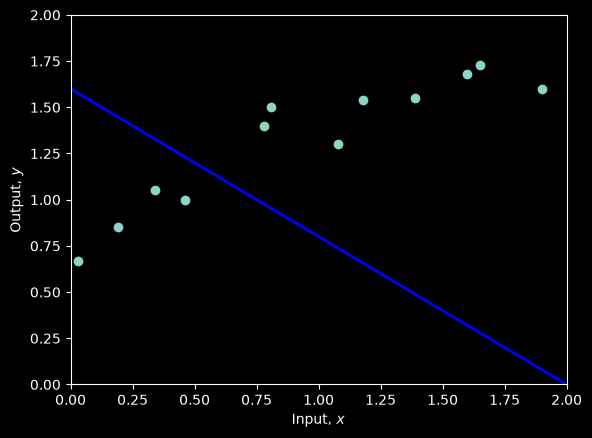

Your Loss = 0.86, Ground truth =10.28


In [9]:
# Set the intercept and slope as in figure 2.2c
phi0 = 1.60 ; phi1 =-0.8
# Plot the data and the model
plot(x,y,phi0,phi1)
loss = compute_loss(x,y,phi0,phi1)
print(f'Your Loss = {loss:3.2f}, Ground truth =10.28')

---

#### Students Turn

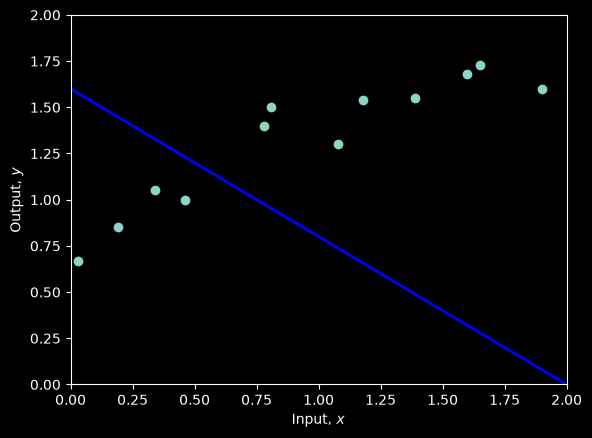

Your Loss = 0.86


In [10]:
# TODO -- Change the parameters manually to fit the model
# First fix phi1 and try changing phi0 until you can't make the loss go down any more
# Then fix phi0 and try changing phi1 until you can't make the loss go down any more
# Repeat this process until you find a set of parameters that fit the model as in figure 2.2d
# You can either do this by hand, or if you want to get fancy, write code to descent automatically in this way
# Start at these values:
phi0 = 1.60 ; phi1 =-0.8

plot(x,y,phi0,phi1)
print(f'Your Loss = {compute_loss(x,y,phi0,phi1):3.2f}')

### 4. Analytic (Closed-Form) Solution

In the previous section, we changed $\phi_0$ and $\phi_1$ manually to reduce the loss.  
For **linear regression with squared-error loss**, we can instead calculate the optimal parameters directly using an **analytic (closed-form) solution**.

Our 1D linear regression model is:

$$
\hat{y}_i = \phi_0 + \phi_1 x_i
$$

where:

- $\phi_0$ is the **bias / intercept**
- $\phi_1$ is the **weight / slope**

#### Step 1: Put the parameters into a vector

We combine the bias and slope into one parameter vector:

$$
\mathbf{w}
=
\begin{bmatrix}
\phi_0 \\
\phi_1
\end{bmatrix}
$$

#### Step 2: Include the bias in the design matrix

To include the bias $\phi_0$ in the matrix multiplication, append a column of ones to the input data:

$$
\mathbf{X}
=
\begin{bmatrix}
1 & x_1 \\
1 & x_2 \\
\vdots & \vdots \\
1 & x_N
\end{bmatrix}
$$

Then all predictions can be written at once as:

$$
\hat{\mathbf{y}} = \mathbf{Xw}
$$

#### Step 3: Define the squared-error objective

We want the predicted values to be as close as possible to the observed values:

$$
L(\mathbf{w}) = \|\mathbf{y}-\mathbf{Xw}\|_2^2
$$

This expression is the **sum of squared errors (SSE)**.  
The MSE used by `compute_loss()` is simply $\frac{1}{N}$ times the SSE, so **SSE and MSE have the same optimal parameters**.

#### Step 4: Find the minimum analytically

Differentiate the loss with respect to $\mathbf{w}$:

$$
\frac{\partial L}{\partial \mathbf{w}}
=
-2\mathbf{X}^{T}(\mathbf{y}-\mathbf{Xw})
$$

At the minimum, set the derivative equal to zero:

$$
\mathbf{X}^{T}\mathbf{Xw}
=
\mathbf{X}^{T}\mathbf{y}
$$

Therefore, the optimal parameter vector is:

$$
\boxed{
\mathbf{w}^{*}
=
(\mathbf{X}^{T}\mathbf{X})^{-1}\mathbf{X}^{T}\mathbf{y}
}
$$

This is called the **normal equation**.

> **Note:** The closed-form solution applies to least-squares linear regression. In practical numerical computing, `np.linalg.solve()` or `np.linalg.pinv()` is often preferred to explicitly computing a matrix inverse, but below we use the inverse form so that the code matches the equation directly.


Design matrix X:
[[1.   0.03]
 [1.   0.19]
 [1.   0.34]
 [1.   0.46]
 [1.   0.78]
 [1.   0.81]
 [1.   1.08]
 [1.   1.18]
 [1.   1.39]
 [1.   1.6 ]
 [1.   1.65]
 [1.   1.9 ]]

Optimal parameters:
phi0 = 0.825950
phi1 = 0.522226

Best-fit linear equation:
y_hat = 0.8260 + 0.5222x

Minimum MSE = 0.016656


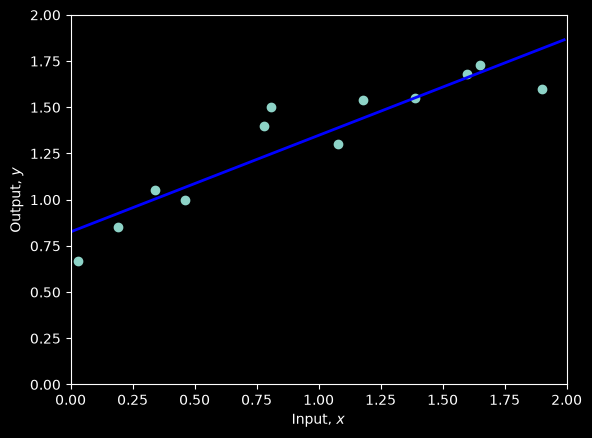

In [11]:
# Analytic (closed-form) solution for 1D linear regression

# Step 1: Construct the design matrix X: 
# The first column contains ones so that the bias phi0
# can be included in the matrix multiplication.


# X = [[1, x1],
#      [1, x2],
#      ...
#      [1, xN]]

X = np.column_stack((np.ones(len(x)), x))

print("Design matrix X:")
print(X)


# Step 2: Apply the normal equation

# w* = (X^T X)^(-1) X^T y
#
# w[0] = phi0  -> bias / intercept
# w[1] = phi1  -> slope / weight

w_opt = np.linalg.inv(X.T @ X) @ X.T @ y

phi0_opt = w_opt[0]
phi1_opt = w_opt[1]


# Step 3: Make predictions using the optimal parameters

y_pred = X @ w_opt


# Step 4: Calculate the MSE

mse = np.mean((y - y_pred) ** 2)


# Step 5: Display the result

print("\nOptimal parameters:")
print(f"phi0 = {phi0_opt:.6f}")
print(f"phi1 = {phi1_opt:.6f}")

print("\nBest-fit linear equation:")
print(f"y_hat = {phi0_opt:.4f} + {phi1_opt:.4f}x")

print(f"\nMinimum MSE = {mse:.6f}")


# Step 6: Plot the optimal regression line

plot(x, y, phi0_opt, phi1_opt)


### 5. Numerical Solutions

The **analytic solution** calculates the optimal parameters directly using a closed-form equation.  
However, many machine-learning and deep-learning models do not have a convenient analytic solution. In those cases, we use a **numerical solution**.

A numerical solution starts with initial parameter values and improves them **iteratively**:

1. Initialize the parameters $\phi_0$ and $\phi_1$.
2. Use the current parameters to make predictions.
3. Calculate the loss.
4. Calculate the gradient of the loss with respect to each parameter.
5. Update the parameters in the direction that reduces the loss.
6. Repeat the process until the model converges.

The general parameter-update rule is:

$$
\phi \leftarrow \phi - \alpha \frac{\partial L}{\partial \phi}
$$

where:

- $\phi$ is a model parameter,
- $\alpha$ is the **learning rate**,
- $\frac{\partial L}{\partial \phi}$ is the **gradient of the loss**.

For our linear model,

$$
\hat{y}_i = \phi_0 + \phi_1x_i
$$

and MSE loss,

$$
L = \frac{1}{N}\sum_{i=1}^{N}(y_i-\hat{y}_i)^2,
$$

the gradients are:

$$
\frac{\partial L}{\partial \phi_0}
=
\frac{2}{N}\sum_{i=1}^{N}(\hat{y}_i-y_i)
$$

$$
\frac{\partial L}{\partial \phi_1}
=
\frac{2}{N}\sum_{i=1}^{N}(\hat{y}_i-y_i)x_i.
$$

We will first review **Batch Gradient Descent**, which uses the complete training set for each update.  
Then we will change it to **Mini-Batch Stochastic Gradient Descent**, which updates the parameters using a small subset of the training data at a time.


#### 5.1 Batch Gradient Descent

**Batch Gradient Descent (GD)** uses **all training samples** to calculate the gradient before updating the parameters.

For one iteration:

$$
\text{all training samples}
\rightarrow
\text{calculate the gradient}
\rightarrow
\text{update the parameters once}
$$

If the dataset contains $N$ samples, the gradient is:

$$
\frac{\partial L}{\partial \phi_0}
=
\frac{2}{N}\sum_{i=1}^{N}(\hat{y}_i-y_i)
$$

$$
\frac{\partial L}{\partial \phi_1}
=
\frac{2}{N}\sum_{i=1}^{N}(\hat{y}_i-y_i)x_i.
$$

Because every parameter update uses the **whole dataset**, the gradient is usually stable and the loss decreases smoothly.

We deliberately start from:

$$
\phi_0=1.60,\qquad \phi_1=-0.80
$$

and let Gradient Descent iteratively move the parameters toward the optimum found earlier by the analytic solution.


Iteration   0: Loss=0.662663, phi0=1.6483, phi1=-0.7082
Iteration  50: Loss=0.080149, phi0=1.2904, phi1=0.1150
Iteration 100: Loss=0.028510, phi0=1.0266, phi1=0.3463
Iteration 150: Loss=0.018869, phi0=0.9127, phi1=0.4462
Iteration 200: Loss=0.017069, phi0=0.8634, phi1=0.4894
Iteration 250: Loss=0.016733, phi0=0.8421, phi1=0.5080
Iteration 300: Loss=0.016670, phi0=0.8329, phi1=0.5161
Iteration 350: Loss=0.016658, phi0=0.8290, phi1=0.5196
Iteration 400: Loss=0.016656, phi0=0.8273, phi1=0.5211
Iteration 450: Loss=0.016656, phi0=0.8265, phi1=0.5217

Batch Gradient Descent result:
phi0 = 0.826198
phi1 = 0.522009
Final MSE = 0.016656

Analytic solution for comparison:
phi0 = 0.825950
phi1 = 0.522226


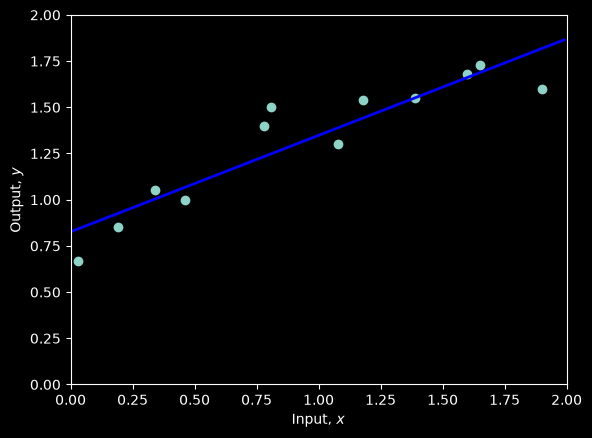

In [12]:

#1. Batch Gradient Descent

learning_rate = 0.05 # Learning rate: controls the step of each update

# Initial parameters
phi0_gd = 1.60
phi1_gd = -0.80

num_iterations = 500  # Number of iterations
N = len(x) # Number of training samples

# Store values so that we can visualize convergence later
gd_loss_history = []
gd_phi0_history = []
gd_phi1_history = []

for i in range(num_iterations):

    # Step 1: Make predictions for ALL training samples
    y_pred = phi0_gd + phi1_gd * x

    # Step 2: Calculate prediction errors
    error = y_pred - y

    # Step 3: Calculate gradients using ALL training samples
    grad_phi0 = (2 / N) * np.sum(error)
    grad_phi1 = (2 / N) * np.sum(error * x)

    # Step 4: Update BOTH parameters
    phi0_gd = phi0_gd - learning_rate * grad_phi0
    phi1_gd = phi1_gd - learning_rate * grad_phi1

    # Step 5: Record the loss and parameters
    loss = compute_loss(x, y, phi0_gd, phi1_gd)

    gd_loss_history.append(loss)
    gd_phi0_history.append(phi0_gd)
    gd_phi1_history.append(phi1_gd)

    # Display progress every 50 iterations
    if i % 50 == 0:
        print(
            f"Iteration {i:3d}: "
            f"Loss={loss:.6f}, "
            f"phi0={phi0_gd:.4f}, "
            f"phi1={phi1_gd:.4f}"
        )

print("\nBatch Gradient Descent result:")
print(f"phi0 = {phi0_gd:.6f}")
print(f"phi1 = {phi1_gd:.6f}")
print(f"Final MSE = {compute_loss(x, y, phi0_gd, phi1_gd):.6f}")

print("\nAnalytic solution for comparison:")
print(f"phi0 = {phi0_opt:.6f}")
print(f"phi1 = {phi1_opt:.6f}")

# Plot the line found by Batch Gradient Descent
plot(x, y, phi0_gd, phi1_gd)


#### 5.2 From Gradient Descent to Mini-Batch Stochastic Gradient Descent

In **Batch Gradient Descent**, we use the entire training dataset before making one parameter update.

In **Mini-Batch Stochastic Gradient Descent**, we divide the training data into several small groups called **mini-batches**.

For example, our dataset has 12 samples. If:

$$
\text{batch size}=4,
$$

then one epoch contains:

$$
12/4=3\text{ mini-batches}.
$$

Therefore, the parameters are updated **3 times during one epoch**.

The process becomes:

$$
\text{shuffle data}
\rightarrow
\text{mini-batch 1}
\rightarrow
\text{update}
\rightarrow
\text{mini-batch 2}
\rightarrow
\text{update}
\rightarrow
\text{mini-batch 3}
\rightarrow
\text{update}.
$$

After all mini-batches have been processed once, we have completed **one epoch**.

For a mini-batch containing $B$ samples, the prediction is still:

$$
\hat{y}_i=\phi_0+\phi_1x_i.
$$

The gradients are calculated using only the samples in the current mini-batch:

$$
\frac{\partial L_B}{\partial \phi_0}
=
\frac{2}{B}
\sum_{i\in B}(\hat{y}_i-y_i)
$$

$$
\frac{\partial L_B}{\partial \phi_1}
=
\frac{2}{B}
\sum_{i\in B}(\hat{y}_i-y_i)x_i.
$$

Then we immediately update the parameters:

$$
\phi_0
\leftarrow
\phi_0-\alpha
\frac{\partial L_B}{\partial \phi_0}
$$

$$
\phi_1
\leftarrow
\phi_1-\alpha
\frac{\partial L_B}{\partial \phi_1}.
$$

### Why use mini-batches?

Mini-batch SGD is a compromise between Batch Gradient Descent and pure SGD:

| Method | Samples used for one update |
|---|---:|
| Batch Gradient Descent | All samples |
| Mini-Batch SGD | A small batch of samples |
| Pure SGD | One sample |

Mini-batches are widely used for training neural networks because they provide efficient vectorized computation while still updating the parameters more frequently than full-batch Gradient Descent.

We also **shuffle the data at the beginning of every epoch** so that the composition of the mini-batches changes across epochs.

> **Terminology note:** Strictly speaking, pure SGD uses `batch_size = 1`.  
> When `1 < batch_size < N`, the method is **Mini-Batch SGD**. In deep-learning libraries and practice, the term **SGD** is also commonly used when the optimizer is trained with mini-batches.


In [ ]:

#2. Mini-Batch Stochastic Gradient Descent

# Initial parameters: same starting point as Batch GD
phi0_mb = 1.60
phi1_mb = -0.80


# Constant parameters
learning_rate_mb = 0.02
batch_size = 4 # Number of samples used for each parameter update
num_epochs = 500 #One epoch
N = len(x) # Number of training samples


# Random generator for reproducible shuffling
rng = np.random.default_rng(42)

# Store values for visualization
mb_loss_history = []
mb_phi0_history = []
mb_phi1_history = []

for epoch in range(num_epochs): # Iteration of trianing

    # Step 1: Shuffle the dataset at the beginning of every epoch
    indices = rng.permutation(N)
    x_shuffled = x[indices] # update x data based on shuffled indix
    y_shuffled = y[indices] #update label data based on shuffled indix

    # TODO: student's activity 
    
    
    # Step 2: Divide the shuffled data into mini-batches
 

    # Step 3: Make predictions for the current mini-batch
    # Prediction error for the current mini-batch

    # Step 4: Calculate gradients using ONLY the current mini-batch

    # Step 5: Update both parameters immediately



    # Step 6: After one epoch, calculate the loss using the complete dataset only for monitoring
    
    loss = compute_loss(x, y, phi0_mb, phi1_mb)

    mb_loss_history.append(loss)
    mb_phi0_history.append(phi0_mb)
    mb_phi1_history.append(phi1_mb)

    if epoch % 50 == 0:
        print(
            f"Epoch {epoch:3d}: "
            f"Loss={loss:.6f}, "
            f"phi0={phi0_mb:.4f}, "
            f"phi1={phi1_mb:.4f}"
        )

print("\nMini-Batch SGD result:")
print(f"Batch size = {batch_size}")
print(f"phi0 = {phi0_mb:.6f}")
print(f"phi1 = {phi1_mb:.6f}")
print(f"Final MSE = {compute_loss(x, y, phi0_mb, phi1_mb):.6f}")

print("\nAnalytic solution for comparison:")
print(f"phi0 = {phi0_opt:.6f}")
print(f"phi1 = {phi1_opt:.6f}")

# Plot the line found by Mini-Batch SGD
plot(x, y, phi0_mb, phi1_mb)


NameError: name 'x' is not defined

#### 5.3 Compare Analytic Solution, Batch GD, and Mini-Batch SGD

All three approaches are trying to find parameters that minimize the same MSE loss.

- **Analytic solution:** computes the least-squares optimum directly.
- **Batch Gradient Descent:** uses all training samples to calculate each gradient and makes one update per iteration.
- **Mini-Batch SGD:** uses a small subset of the training data for each gradient and makes several updates during each epoch.

For our dataset:

- Number of training samples: $N=12$
- Mini-batch size: $B=4$
- Number of mini-batches per epoch: $12/4=3$

Therefore, Mini-Batch SGD performs **3 parameter updates per epoch**.

The numerical solutions should approach the analytic solution, although their exact values depend on the learning rate, number of iterations or epochs, mini-batch size, and shuffled data order.

### Parameter updates in this example

With 12 samples:

- **Batch GD:** uses all 12 samples, then updates the parameters once.
- **Mini-Batch SGD with batch size 4:** processes 4 samples, updates; another 4 samples, updates; final 4 samples, updates.
- Therefore, one Mini-Batch SGD epoch contains **3 parameter updates**.

Changing the batch size changes how frequently the parameters are updated:

$$
\text{updates per epoch}
=
\left\lceil \frac{N}{B} \right\rceil
$$

where $N$ is the number of training samples and $B$ is the mini-batch size.


In [17]:

# Compare the three optimization approaches

analytic_loss = compute_loss(x, y, phi0_opt, phi1_opt)
gd_loss = compute_loss(x, y, phi0_gd, phi1_gd)
mb_loss = compute_loss(x, y, phi0_mb, phi1_mb)

print("Method                    phi0       phi1       MSE")
print("-" * 62)

print(
    f"Analytic Solution       "
    f"{phi0_opt:9.6f}  {phi1_opt:9.6f}  {analytic_loss:.6f}"
)

print(
    f"Batch GD                "
    f"{phi0_gd:9.6f}  {phi1_gd:9.6f}  {gd_loss:.6f}"
)

print(
    f"Mini-Batch SGD (B={batch_size}) "
    f"{phi0_mb:9.6f}  {phi1_mb:9.6f}  {mb_loss:.6f}"
)


Method                    phi0       phi1       MSE
--------------------------------------------------------------
Analytic Solution        0.825950   0.522226  0.016656
Batch GD                 0.826198   0.522009  0.016656
Mini-Batch SGD (B=4)  0.826752   0.522067  0.016656


### 6. Visualizing the Loss Function and Optimization

The loss surface shows the MSE for different combinations of $\phi_0$ and $\phi_1$.

The **analytic solution** identifies the minimum directly.

The numerical methods move toward the minimum through repeated parameter updates:

- **Batch GD** uses the whole dataset for every update, so its optimization path is generally smoother.
- **Mini-Batch SGD** uses only a subset of the data for each update. Its gradient is therefore an estimate of the full-dataset gradient, so the optimization path can fluctuate slightly while moving toward the minimum.

This stochastic behavior is one reason mini-batch optimization works well for large datasets and neural-network training.


In [18]:
# Make a 2D grid of possible phi0 and phi1 values
phi0_mesh, phi1_mesh = np.meshgrid(
    np.arange(0.0, 2.0, 0.02),
    np.arange(-1.0, 1.0, 0.02)
)
# Calculate the MSE for every combination of phi0 and phi1
all_losses = np.zeros_like(phi1_mesh)

for indices, _ in np.ndenumerate(phi1_mesh):
    all_losses[indices] = compute_loss(
        x,
        y,
        phi0_mesh[indices],
        phi1_mesh[indices]
    )


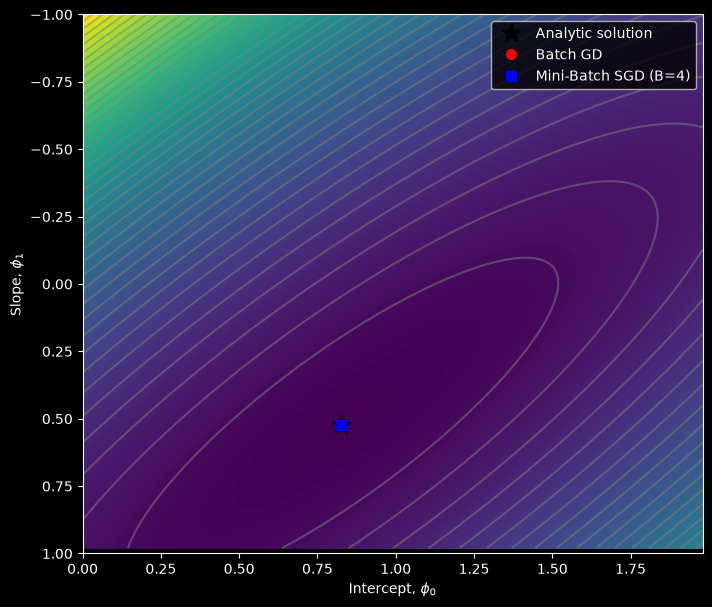

In [19]:
# Plot the loss surface and the final solutions

fig = plt.figure()
ax = plt.axes()
fig.set_size_inches(8, 7)

# Loss surface
ax.contourf(phi0_mesh, phi1_mesh, all_losses, levels=256)
ax.contour(
    phi0_mesh,
    phi1_mesh,
    all_losses,
    levels=40,
    colors=['#80808080']
)

# Mark the final parameter values
ax.plot(phi0_opt, phi1_opt, 'k*', markersize=14, label='Analytic solution')
ax.plot(phi0_gd, phi1_gd, 'ro', markersize=7, label='Batch GD')
ax.plot(phi0_mb, phi1_mb, 'bs', markersize=7,
        label=f'Mini-Batch SGD (B={batch_size})')

ax.set_ylim([1, -1])
ax.set_xlabel(r'Intercept, $\phi_0$')
ax.set_ylabel(r'Slope, $\phi_1$')
ax.legend()

plt.show()
